# 01 · Análisis exploratorio: Severstal Steel Defect Detection


1. Distribución de clases y desbalance.
2. Co-ocurrencia de clases y número de defectos por imagen.
3. Tamaño de los defectos por clase (justifica `--min-area` y el uso de tiles).
4. Verificación visual de la decodificación RLE (orden de columna).
5. Distribución de clases en las particiones train/val/test.

In [7]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import RAW_DIR, SPLIT_CSV, FIG_DIR, CLASS_NAMES, NUM_CLASSES
from utils import load_annotations, group_annotations, build_masks, rle_decode, overlay_masks

FIG_DIR.mkdir(parents=True, exist_ok=True)
COLORS = ["#F2A900", "#C2185B", "#D32F2F", "#2E7D32"]   # misma paleta que la demo
ann = load_annotations(RAW_DIR / "train.csv")
images = sorted(p.name for p in (RAW_DIR / "train_images").glob("*.jpg"))
ann_by_image = group_annotations(ann)
print(f"Imágenes etiquetadas: {len(images)}")
print(f"Imágenes con al menos un defecto: {ann.ImageId.nunique()} ({100*ann.ImageId.nunique()/len(images):.1f} %)")
print(f"Imágenes sin defecto: {len(images) - ann.ImageId.nunique()}")

Imágenes etiquetadas: 12568
Imágenes con al menos un defecto: 6666 (53.0 %)
Imágenes sin defecto: 5902


## 1. Distribución de clases

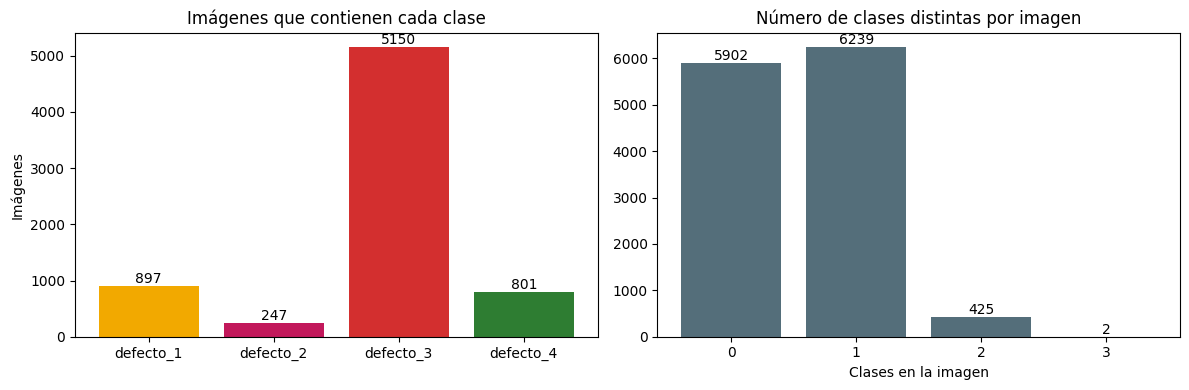

Razón de desbalance (clase más común / más rara): 20.9


In [8]:
per_class = ann.groupby("ClassId").ImageId.nunique().reindex(range(1, 5), fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(CLASS_NAMES, per_class.values, color=COLORS)
for i, v in enumerate(per_class.values):
    ax[0].text(i, v, str(v), ha="center", va="bottom")
ax[0].set_title("Imágenes que contienen cada clase")
ax[0].set_ylabel("Imágenes")

n_def = pd.Series(images).map(lambda x: len({c for c, _ in ann_by_image.get(x, [])})).value_counts().sort_index()
ax[1].bar(n_def.index.astype(str), n_def.values, color="#546E7A")
for i, v in zip(n_def.index, n_def.values):
    ax[1].text(str(i), v, str(v), ha="center", va="bottom")
ax[1].set_title("Número de clases distintas por imagen")
ax[1].set_xlabel("Clases en la imagen")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_distribucion_clases.png", dpi=130)
plt.show()
print("Razón de desbalance (clase más común / más rara):", round(per_class.max() / per_class.min(), 1))

## 2. Co-ocurrencia de clases

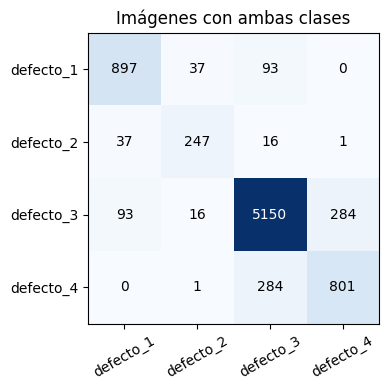

In [9]:
multi = pd.crosstab(ann.ImageId, ann.ClassId).clip(upper=1).reindex(columns=range(1, 5), fill_value=0)
co = multi.T @ multi
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(co, cmap="Blues")
for (i, j), v in np.ndenumerate(co.values):
    ax.text(j, i, v, ha="center", va="center", color="white" if v > co.values.max()/2 else "black")
ax.set_xticks(range(4), CLASS_NAMES, rotation=30)
ax.set_yticks(range(4), CLASS_NAMES)
ax.set_title("Imágenes con ambas clases")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_coocurrencia.png", dpi=130)
plt.show()

## 3. Tamaño de los defectos (componentes conexos)

           count     mean      std    min     5%     50%      95%       max
ClassId                                                                    
1         3082.0   1269.0   1272.0   90.0  368.0   878.0   3515.0   17467.0
2          321.0   2600.0   1594.0  216.0  673.0  2278.0   5709.0    9641.0
3        14648.0   8964.0  19133.0    1.0  230.0  4206.0  35614.0  329859.0
4         1907.0  14438.0  18953.0    1.0  594.0  7701.0  50860.0  168151.0


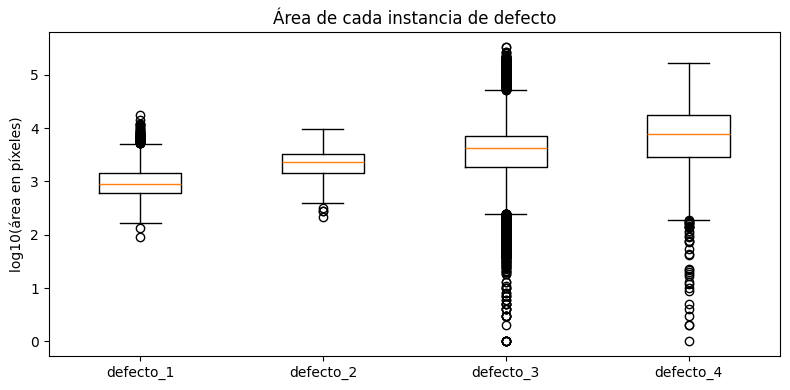

Instancias con área < 30 px (se descartan como ruido): 0.33 %
Instancias más anchas que un tile de 320 px: 5.4 %


In [ ]:
rows = []
for img, cls, rle in ann.itertuples(index=False):
    m = rle_decode(rle)
    n, _, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    for k in range(1, n):
        x, y, w, h, area = stats[k]
        rows.append({"ClassId": cls, "area": area, "ancho": w, "alto": h})
comp = pd.DataFrame(rows)
print(comp.groupby("ClassId").area.describe(percentiles=[.05, .5, .95]).round(0))

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([np.log10(comp.loc[comp.ClassId == c, "area"]) for c in range(1, 5)], tick_labels=CLASS_NAMES)
ax.set_ylabel("log10(área en píxeles)")
ax.set_title("Área de cada instancia de defecto")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_area_defectos.png", dpi=130)
plt.show()
print(f"Instancias con área < 30 px (se descartan como ruido): {(comp.area < 30).mean()*100:.2f} %")
print(f"Instancias más anchas que un tile de 320 px: {(comp.ancho > 320).mean()*100:.1f} %")

## 4. Verificación visual del RLE (una imagen por clase)

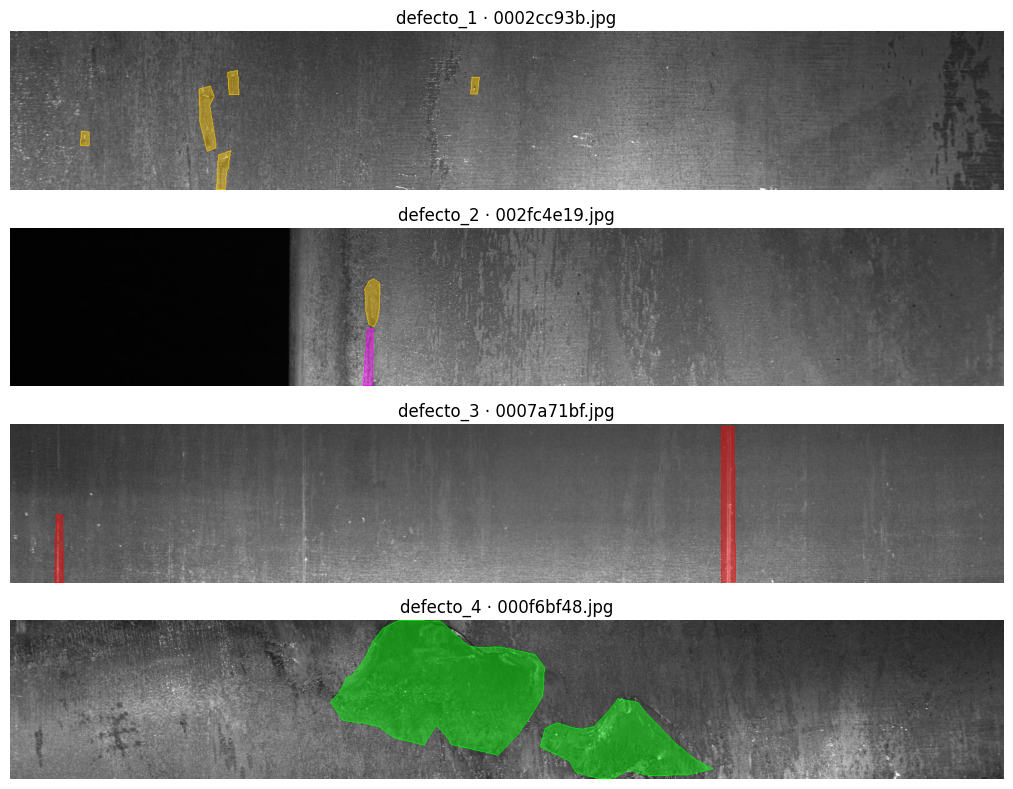

In [11]:
fig, axes = plt.subplots(4, 1, figsize=(14, 8))
for c, ax in zip(range(1, 5), axes):
    img_id = ann.loc[ann.ClassId == c, "ImageId"].iloc[0]
    gray = cv2.imread(str(RAW_DIR / "train_images" / img_id), cv2.IMREAD_GRAYSCALE)
    vis = overlay_masks(gray, build_masks(ann_by_image, img_id))
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{CLASS_NAMES[c-1]} · {img_id}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_ejemplos_por_clase.png", dpi=130)
plt.show()

## 5. Distribución en las particiones (requiere `src/prepare_split.py`)

In [12]:
split = pd.read_csv(SPLIT_CSV)
tab = split.groupby("split")[[f"has_c{c}" for c in range(1, 5)]].mean().mul(100).round(2)
tab.columns = CLASS_NAMES
tab["sin_defecto"] = split.groupby("split").n_classes.apply(lambda s: (s == 0).mean() * 100).round(2)
print("% de imágenes con cada clase por partición:")
tab.loc[["train", "val", "test"]]

% de imágenes con cada clase por partición:


,defecto_1,defecto_2,defecto_3,defecto_4,sin_defecto
split,,,,,
train,6.98,1.97,41.59,6.46,46.48
val,7.02,1.45,39.83,6.35,48.36
test,7.98,2.46,39.13,6.00,47.91


## 6. Desbalance detectado y estrategia

Se detecto un desvalance en las clases, la clase 3 domina; la clase 2 es muy rara; y la mitad de las imágenes no tiene defectos.

Dado el EDA podemos concluir:
- **Imágenes sin defecto:** 5,902 de 12,568 (47 %).
- **Imágenes por clase:** clase 1 = 897, clase 2 = 247, clase 3 = 5150, clase 4 = 801.
- **Razón de desbalance:** la clase más común tiene 21 veces más imágenes que la más rara.
- **Clases por imagen:** 93.59 % de las imágenes con defecto tiene una sola clase; la combinación más frecuente es clase 3 con clase 4. 
- **Tamaño de los defectos:** la clase 2 tiene los defectos más pequeños (mediana 2600 px) y la clase 3 los más grandes (mediana 8964 px).
- **Defectos más anchos que un tile de 320 px:** 5.4 %. Por eso un mismo defecto puede quedar repartido en varios tiles.
- **Defectos menores a 30 píxeles:** Se elimina una cantidad muy pequeña de regiones de defectos (0.33 %) porque son demasiado pequeñas y podrían ser ruido en los datos.
- **Particiones:** la clase 2 aparece en train (1.97 %), val (1.45 %) y test (2.46 %).

### Estrategia para atender el desbalance

1. **Particiones estratificadas** por la clase más rara presente en cada imagen, para que la clase 2 aparezca en las tres particiones (comprobado en la sección 5).
2. **Submuestreo de fondo:** en entrenamiento solo se conserva el 25 % de los tiles sin defecto (`--neg-keep 0.25`), para que el modelo no aprenda a responder siempre "sin defecto".
3. **Aumento de datos:** volteo horizontal y vertical, y cambios de brillo. No se usan cambios de color porque las imágenes están en escala de grises.
4. **Umbral de confianza por clase**, elegido en validación para maximizar el F1 de cada clase. Así la clase 2 no queda castigada por un umbral pensado para la clase 3.
5. **Métricas que no se dejan engañar por el desbalance:** F1 macro y Dice por clase, en lugar de exactitud global.
6. **Plan B si la clase 2 sale con F1 bajo:** sobremuestrearla, es decir, repetir sus imágenes en entrenamiento.

